In [1]:
import os
import requests
import cdsapi
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## CHANGE DIRECTORYYYY
OUTPUT_DIR = "../../01_data/1.2_raw_api/era5_hourly_temp"
os.makedirs(OUTPUT_DIR, exist_ok=True)

GEO_DIR = "../../01_data/1.3_raw_other/mapping"
os.makedirs(GEO_DIR, exist_ok=True)

CLEANED_DIR = "../../01_data/2_cleaned/weather"
os.makedirs(CLEANED_DIR, exist_ok=True)

<Axes: >

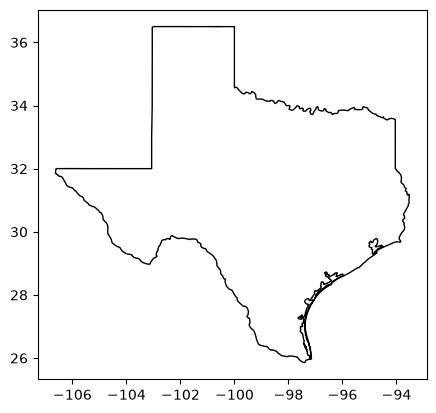

In [2]:
# Texas state boundary, for clipping the bbox download down to the actual state shape
TEXAS_GEOJSON_URL = "https://raw.githubusercontent.com/glynnbird/usstatesgeojson/master/texas.geojson"
texas_geojson_path = os.path.join(GEO_DIR, "texas_state_boundary.geojson")

if not os.path.exists(texas_geojson_path):
    resp = requests.get(TEXAS_GEOJSON_URL, timeout=30)
    resp.raise_for_status()
    with open(texas_geojson_path, "wb") as f:
        f.write(resp.content)

texas_gdf = gpd.read_file(texas_geojson_path).to_crs("EPSG:4326")
texas_boundary = texas_gdf.union_all()
texas_gdf.plot(edgecolor="black", facecolor="none")

In [3]:
# Texas geo box
# North, West, South, East
AREA = [37, -107, 25.5, -93]

In [4]:
from dotenv import load_dotenv

load_dotenv()
CDS_API_URL = os.environ["CDS_API_URL"]
CDS_API_KEY = os.environ["CDS_API_KEY"]  # https://cds.climate.copernicus.eu/profile
client = cdsapi.Client(url=CDS_API_URL, key=CDS_API_KEY)

2026-10-28 13:50:04,184 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


In [5]:
# 1. Define the desired time range in Central Prevailing Time (CPT), convert to UTC
#    i.e. ERCOT local wall-clock time (America/Chicago, DST-observing).
CPT = "America/Chicago"
start_cpt = pd.Timestamp("2021-01-01 00:00", tz=CPT)
end_cpt   = pd.Timestamp("2021-01-31 23:00", tz=CPT)

start_utc = start_cpt.tz_convert("UTC")
end_utc = end_cpt.tz_convert("UTC")

print(f'{start_utc} -> {end_utc}')

# define tail end gap
# Jan + 5 hours in Feb


2021-01-01 06:00:00+00:00 -> 2021-02-01 05:00:00+00:00


In [6]:
# 2. Download: main month (full UTC calendar month) + boundary hours
#    Option A: two small requests instead of one bloated cartesian product.

def retrieve_if_missing(client, request, out_path):
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"Skipping (already exists): {out_path}")
        return
    client.retrieve("reanalysis-era5-single-levels", request, out_path)
    print(f"Saved: {out_path}")

# main request: full January in UTC
main_nc = os.path.join(OUTPUT_DIR, "era5_texas_t2m_hourly_test_main.nc")
retrieve_if_missing(client, {
    "product_type": ["reanalysis"],
    "variable": ["2m_temperature"],
    "year": [str(start_utc.year)],
    "month": [f"{start_utc.month:02d}"],
    "day": [f"{d:02d}" for d in range(1, 32)],
    "time": [f"{h:02d}:00" for h in range(24)],
    "area": AREA,
    "data_format": "netcdf",
    "download_format": "unarchived",
}, main_nc)

# boundary request: only the extra UTC hours that spill into the next month
# e.g. Feb 1 00:00–05:00 UTC for CPT Jan 31 18:00–23:00
boundary_nc = os.path.join(OUTPUT_DIR, "era5_texas_t2m_hourly_test_boundary.nc")
boundary_hours = [f"{h:02d}:00" for h in range(end_utc.hour + 1)]
retrieve_if_missing(client, {
    "product_type": ["reanalysis"],
    "variable": ["2m_temperature"],
    "year": [str(end_utc.year)],
    "month": [f"{end_utc.month:02d}"],
    "day": [f"{end_utc.day:02d}"],
    "time": boundary_hours,
    "area": AREA,
    "data_format": "netcdf",
    "download_format": "unarchived",
}, boundary_nc)

print(f"Main: {start_utc.month:02d}/{start_utc.year}, all days/hours")
print(f"Boundary: {end_utc.year}-{end_utc.month:02d}-{end_utc.day:02d}, hours {boundary_hours}")

Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_test_main.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_test_boundary.nc
Main: 01/2021, all days/hours
Boundary: 2021-02-01, hours ['00:00', '01:00', '02:00', '03:00', '04:00', '05:00']


In [7]:
# 3. Mask to Texas boundary, average, convert UTC -> CPT (hour-ending)
def get_texas_mean(nc_paths, start_cpt=None, end_cpt=None):
    if isinstance(nc_paths, str):
        nc_paths = [nc_paths]

    ds = xr.concat([xr.open_dataset(p) for p in nc_paths], dim="valid_time")

    lon2d, lat2d = np.meshgrid(ds["longitude"].values, ds["latitude"].values)
    grid_points = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(lon2d.ravel(), lat2d.ravel()),
        crs="EPSG:4326",
    )
    in_texas = grid_points.within(texas_boundary).values.reshape(lat2d.shape)

    texas_mask = xr.DataArray(
        in_texas,
        dims=("latitude", "longitude"),
        coords={"latitude": ds["latitude"], "longitude": ds["longitude"]},
    )
    
    ds_texas = ds.where(texas_mask)

    t2m_hourly_mean = ds_texas["t2m"].mean(dim=["latitude", "longitude"])

    t2m_hourly_mean_df = t2m_hourly_mean.to_dataframe(name="t2m_mean_K").reset_index()
    t2m_hourly_mean_df["t2m_mean_F"] = (t2m_hourly_mean_df["t2m_mean_K"] - 273.15) * 9 / 5 + 32

    df = t2m_hourly_mean_df.filter(['valid_time', 't2m_mean_F'])

    # Convert UTC valid_time -> CPT, shift +1h to hour-ending to match ERCOT,
    # then drop tz for merge.
    valid_time_cpt = (
        pd.to_datetime(df['valid_time'], utc=True)
          .dt.tz_convert(CPT)
        + pd.Timedelta(hours=1)
    )
    df['valid_time'] = valid_time_cpt.dt.tz_localize(None)

    # Trim to exact CPT window (already hour-ending)
    if start_cpt is not None and end_cpt is not None:
        he_start = start_cpt + pd.Timedelta(hours=1)
        he_end   = end_cpt   + pd.Timedelta(hours=1)
        mask = (valid_time_cpt >= he_start) & (valid_time_cpt <= he_end)
        df = df[mask.values].reset_index(drop=True)

    # DST fall-back: two UTC hours collapse to the same naive CPT hour;
    # average them so the output has one unique row per local hour.
    df = df.groupby("valid_time", as_index=False)["t2m_mean_F"].mean()

    df = df.rename(columns={'valid_time': 'datetime', 't2m_mean_F': 'tx_temp'})
    return df

In [8]:
df = get_texas_mean([main_nc, boundary_nc], start_cpt=start_cpt, end_cpt=end_cpt)
df

,datetime,tx_temp
0,2021-01-01 01:00:00,35.301445
1,2021-01-01 02:00:00,34.923515
2,2021-01-01 03:00:00,34.651550
3,2021-01-01 04:00:00,33.962486
4,2021-01-01 05:00:00,32.179901
...,...,...
739,2021-01-31 20:00:00,56.472923
740,2021-01-31 21:00:00,53.850761
741,2021-01-31 22:00:00,47.788727
742,2021-01-31 23:00:00,47.092247


In [9]:
df.to_csv(os.path.join(CLEANED_DIR, f'Texas Hourly Temperature Average test.csv'), index=False)

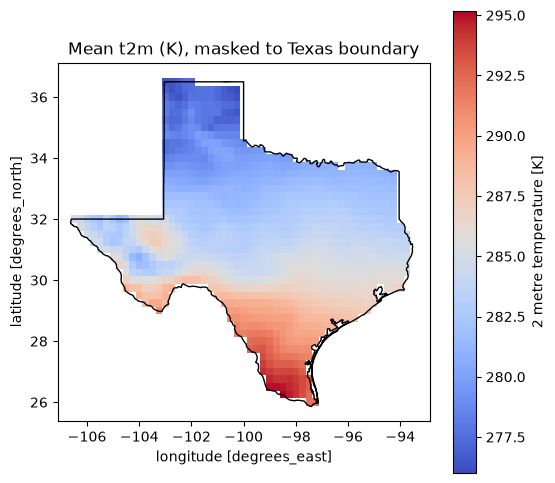

In [10]:
# sanity check: shaded region should trace the Texas outline, not the bbox rectangle
nc_path = os.path.join(OUTPUT_DIR, f"era5_texas_t2m_hourly_test_boundary.nc")
ds = xr.open_dataset(nc_path)

lon2d, lat2d = np.meshgrid(ds["longitude"].values, ds["latitude"].values)
grid_points = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(lon2d.ravel(), lat2d.ravel()),
        crs="EPSG:4326",
    )
in_texas = grid_points.within(texas_boundary).values.reshape(lat2d.shape)

texas_mask = xr.DataArray(
        in_texas,
        dims=("latitude", "longitude"),
        coords={"latitude": ds["latitude"], "longitude": ds["longitude"]},
    )
    
ds_texas = ds.where(texas_mask)

fig, ax = plt.subplots(figsize=(6, 6))
ds_texas["t2m"].mean("valid_time").plot(ax=ax, x="longitude", y="latitude", cmap="coolwarm")
texas_gdf.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Mean t2m (K), masked to Texas boundary")
plt.show()

---
## 2026 extension — 2026-01-01 → latest available

Extends the 2021–2025 series (`Texas_hourly_temp_2021_2025.csv`) for the post-RTC+B adder
model (adders start 2025-12-05). Same request, mask, and CPT hour-ending conversion as above.

- ERA5 lags real time by ~5 days, and the newest ~2–3 months come as **ERA5T** (preliminary,
  `expver` 0005), which is later replaced by final ERA5 (`expver` 0001).
- The CPT 2025-12-31 tail hours were already pulled (`era5_texas_t2m_hourly_2026_boundary.nc`),
  so the 2026 window starts at CPT 2026-01-01 HE 01.

In [11]:
# 4. 2026 window in CPT. ERA5 lags real time by ~5 days, so stop at the last full CPT day
#    the CDS can serve; requesting dates past that makes the request fail.
import calendar

LATENCY_DAYS = 6
last_utc_day = pd.Timestamp.now(tz="UTC").normalize() - pd.Timedelta(days=LATENCY_DAYS)

start_cpt_26 = pd.Timestamp("2026-01-01 00:00", tz=CPT)
end_cpt_26   = pd.Timestamp(last_utc_day.date(), tz=CPT) - pd.Timedelta(hours=1)  # prior CPT day 23:00

start_utc_26 = start_cpt_26.tz_convert("UTC")
end_utc_26   = end_cpt_26.tz_convert("UTC")
print(f"CPT: {start_cpt_26} -> {end_cpt_26}")
print(f"UTC: {start_utc_26} -> {end_utc_26}")

CPT: 2026-01-01 00:00:00-06:00 -> 2026-10-21 23:00:00-05:00
UTC: 2026-01-01 06:00:00+00:00 -> 2026-10-22 04:00:00+00:00


In [12]:
# 5. Download 2026 one UTC month per request. Full months get a final name; the trailing
#    partial month is named by its last day, so a later rerun pulls a fresh file.
assert last_utc_day.year == 2026

nc_paths_26 = []
for month in range(1, last_utc_day.month + 1):
    full_days = calendar.monthrange(2026, month)[1]
    partial = month == last_utc_day.month and last_utc_day.day < full_days
    n_days = last_utc_day.day if partial else full_days
    suffix = f"2026_{month:02d}" + (f"_to{n_days:02d}" if partial else "")
    out_nc = os.path.join(OUTPUT_DIR, f"era5_texas_t2m_hourly_{suffix}.nc")
    retrieve_if_missing(client, {
        "product_type": ["reanalysis"],
        "variable": ["2m_temperature"],
        "year": ["2026"],
        "month": [f"{month:02d}"],
        "day": [f"{d:02d}" for d in range(1, n_days + 1)],
        "time": [f"{h:02d}:00" for h in range(24)],
        "area": AREA,
        "data_format": "netcdf",
        "download_format": "unarchived",
    }, out_nc)
    nc_paths_26.append(out_nc)

Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_01.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_02.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_03.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_04.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_05.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_06.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_07.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_08.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era5_texas_t2m_hourly_2026_09.nc
Skipping (already exists): ../../01_data/1.2_raw_api/era5_hourly_temp/era

In [13]:
# 6. ERA5T check: the latest ~2–3 months are preliminary (expver 0005) and are later
#    replaced by final ERA5 (0001); record which months are still preliminary.
rows = []
for p in nc_paths_26:
    # close each file: re-opening a still-open netCDF later (cell 8) crashes the kernel
    with xr.open_dataset(p) as ds:
        ev = ds["expver"].values if "expver" in ds.variables else np.array(["n/a"])
        rows.append({
            "file"     : os.path.basename(p),
            "first_utc": pd.Timestamp(ds["valid_time"].values.min()),
            "last_utc" : pd.Timestamp(ds["valid_time"].values.max()),
            "hours"    : ds.sizes["valid_time"],
            "expver"   : ", ".join(sorted(map(str, np.unique(ev)))),
        })
display(pd.DataFrame(rows))

# same lat/lon grid as 2025 → the Texas mask (and statewide mean) is identical across years
with xr.open_dataset(os.path.join(OUTPUT_DIR, "era5_texas_t2m_hourly_2025.nc")) as ds25, \
     xr.open_dataset(nc_paths_26[0]) as ds26:
    print("same lat/lon grid as 2025:",
          ds25["latitude"].equals(ds26["latitude"]) and ds25["longitude"].equals(ds26["longitude"]))

,file,first_utc,last_utc,hours,expver
0,era5_texas_t2m_hourly_2026_01.nc,2026-01-01,2026-01-31 23:00:00,744,0001
1,era5_texas_t2m_hourly_2026_02.nc,2026-02-01,2026-02-28 23:00:00,672,0001
2,era5_texas_t2m_hourly_2026_03.nc,2026-03-01,2026-03-31 23:00:00,744,0001
3,era5_texas_t2m_hourly_2026_04.nc,2026-04-01,2026-04-30 23:00:00,720,0001
4,era5_texas_t2m_hourly_2026_05.nc,2026-05-01,2026-05-31 23:00:00,744,0001
5,era5_texas_t2m_hourly_2026_06.nc,2026-06-01,2026-06-30 23:00:00,720,0001
6,era5_texas_t2m_hourly_2026_07.nc,2026-07-01,2026-07-31 23:00:00,744,0001
7,era5_texas_t2m_hourly_2026_08.nc,2026-08-01,2026-08-31 23:00:00,744,0001
8,era5_texas_t2m_hourly_2026_09.nc,2026-09-01,2026-09-30 23:00:00,720,0005
9,era5_texas_t2m_hourly_2026_10_to22.nc,2026-10-01,2026-10-22 23:00:00,528,0005


same lat/lon grid as 2025: True


In [14]:
# 7. Mask, average, convert to CPT hour-ending (same get_texas_mean as above), then validate
df26 = get_texas_mean(nc_paths_26, start_cpt=start_cpt_26, end_cpt=end_cpt_26)

expected = pd.date_range(start_cpt_26 + pd.Timedelta(hours=1),
                         end_cpt_26 + pd.Timedelta(hours=1), freq="h").tz_localize(None)
missing = expected.difference(pd.DatetimeIndex(df26["datetime"]))
n_dupes = df26["datetime"].duplicated().sum()
n_nan = df26["tx_temp"].isna().sum()

print(f"rows={len(df26)} | expected={expected.nunique()} | missing={len(missing)} | "
      f"dupes={n_dupes} | nan={n_nan} | "
      f"range=[{df26['tx_temp'].min():.1f}, {df26['tx_temp'].max():.1f}] °F")
assert len(missing) == 0 and n_dupes == 0 and n_nan == 0
df26

rows=7055 | expected=7055 | missing=0 | dupes=0 | nan=0 | range=[14.9, 102.8] °F


,datetime,tx_temp
0,2026-01-01 01:00:00,46.987713
1,2026-01-01 02:00:00,46.622913
2,2026-01-01 03:00:00,44.899982
3,2026-01-01 04:00:00,44.732002
4,2026-01-01 05:00:00,42.885857
...,...,...
7050,2026-10-21 20:00:00,76.622566
7051,2026-10-21 21:00:00,74.201889
7052,2026-10-21 22:00:00,70.058235
7053,2026-10-21 23:00:00,68.383095


In [15]:
# 8. Splice check against the 2021–2025 cleaned file:
#    (a) no overlap / gap at the join
#    (b) Dec 31 HE 19–24 rebuilt from the Jan-2026 pull (UTC Jan 1 00:00–05:00) match the
#        values the 2025 boundary pull wrote — same ERA5 hours from two separate requests
df_hist = pd.read_csv(os.path.join(CLEANED_DIR, "Texas_hourly_temp_2021_2025.csv"), parse_dates=["datetime"])
df_hist = df_hist.sort_values("datetime").reset_index(drop=True)
print("2025 file ends:", df_hist["datetime"].max(), "| 2026 starts:", df26["datetime"].min())
print("overlap rows:", df26["datetime"].isin(df_hist["datetime"]).sum())

rebuilt = get_texas_mean(nc_paths_26[0],
                         start_cpt=pd.Timestamp("2025-12-31 18:00", tz=CPT),
                         end_cpt=pd.Timestamp("2025-12-31 23:00", tz=CPT))
cmp = rebuilt.merge(df_hist, on="datetime", suffixes=("_2026pull", "_2025pull"))
cmp["diff_F"] = cmp["tx_temp_2026pull"] - cmp["tx_temp_2025pull"]
print("max |diff| on re-pulled hours (°F):", cmp["diff_F"].abs().max())

step = df26["tx_temp"].iloc[0] - df_hist["tx_temp"].iloc[-1]
typical = df_hist["tx_temp"].diff().abs().quantile(0.99)
print(f"step at join: {step:.2f} °F  (99th pct hourly |Δ| 2021–2025: {typical:.2f} °F)")
cmp

2025 file ends: 2026-01-01 00:00:00 | 2026 starts: 2026-01-01 01:00:00
overlap rows: 0


max |diff| on re-pulled hours (°F): 1.2695312534560799e-06
step at join: -0.80 °F  (99th pct hourly |Δ| 2021–2025: 6.91 °F)


,datetime,tx_temp_2026pull,tx_temp_2025pull,diff_F
0,2025-12-31 19:00:00,57.400940,57.400940,-5.859375e-08
1,2025-12-31 20:00:00,56.684467,56.684467,3.156738e-07
2,2025-12-31 21:00:00,51.554237,51.554237,3.657227e-07
3,2025-12-31 22:00:00,50.368977,50.368977,-4.069824e-07
4,2025-12-31 23:00:00,49.432446,49.432446,-4.738770e-07
5,2026-01-01 00:00:00,47.791199,47.791200,-1.269531e-06


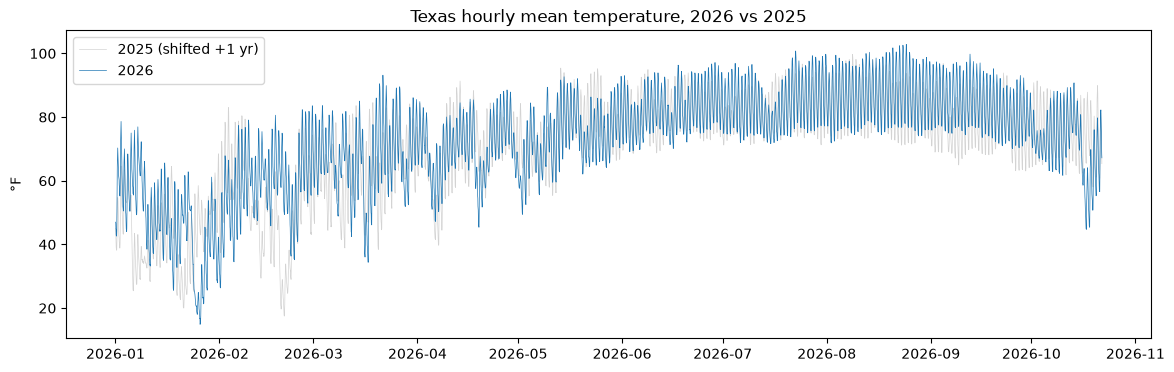

In [16]:
# 9. Eyeball: 2026 against the same calendar days of 2025
h25 = df_hist[(df_hist["datetime"] >= "2025-01-01")
              & (df_hist["datetime"] <= df26["datetime"].max() - pd.DateOffset(years=1))]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(h25["datetime"] + pd.DateOffset(years=1), h25["tx_temp"], lw=0.5, color="lightgray", label="2025 (shifted +1 yr)")
ax.plot(df26["datetime"], df26["tx_temp"], lw=0.5, label="2026")
ax.set_ylabel("°F")
ax.legend()
ax.set_title("Texas hourly mean temperature, 2026 vs 2025")
plt.show()

In [17]:
# 10. Export 2026 YTD as its own cleaned file (the 2021–2025 file is left untouched)
end_tag = end_cpt_26.strftime("%Y%m%d")
out_csv = os.path.join(CLEANED_DIR, f"Texas_hourly_temp_20260101_{end_tag}.csv")
df26.to_csv(out_csv, index=False)
print("wrote", out_csv, df26.shape)

wrote ../../01_data/2_cleaned/weather/Texas_hourly_temp_20260101_20261021.csv (7055, 2)


In [18]:
# 11. RTC+B-window export: 2025-12-05 HE1 (RTC+B go-live, matches the adder data) → latest
#     2026 hour, spliced from the 2021–2025 and 2026 cleaned files
RTCB_START = pd.Timestamp("2025-12-05 01:00")

df_hist = pd.read_csv(os.path.join(CLEANED_DIR, "Texas_hourly_temp_2021_2025.csv"), parse_dates=["datetime"])
df_rtcb = pd.concat([df_hist[df_hist["datetime"] >= RTCB_START], df26], ignore_index=True)
df_rtcb = df_rtcb.sort_values("datetime").reset_index(drop=True)

# expected hours in CPT, so the spring-forward hour (absent from the data) isn't expected
expected = pd.date_range(RTCB_START.tz_localize(CPT), df_rtcb["datetime"].max().tz_localize(CPT),
                         freq="h").tz_localize(None)
assert df_rtcb["datetime"].is_unique and df_rtcb["tx_temp"].notna().all()
assert expected.difference(pd.DatetimeIndex(df_rtcb["datetime"])).empty

out_csv = os.path.join(CLEANED_DIR, f"Texas_hourly_temp_20251205_{end_tag}.csv")
df_rtcb.to_csv(out_csv, index=False)
print("wrote", out_csv, df_rtcb.shape, df_rtcb["datetime"].min(), "->", df_rtcb["datetime"].max())

wrote ../../01_data/2_cleaned/weather/Texas_hourly_temp_20251205_20261021.csv (7703, 2) 2025-12-05 01:00:00 -> 2026-10-22 00:00:00


---
## Decision checklist (human) — 2026 extension

- [ ] Window end (cell 4) acceptable, or pull again closer to the modeling date?
- [ ] ERA5T months (cell 6, `expver` 0005) used as-is, or re-pulled once final ERA5 replaces them?
- [ ] Splice (cell 8): Dec 31 hours match the 2025 pull and the step at the join looks normal?
- [ ] Keep 2026 as its own cleaned file, or fold into one `Texas_hourly_temp_2021_<end>.csv`?

Then: extend `era5_ercot_temp.py` (`END_YEAR`, partial-year end) to match.